# PUNTO 1 - Actualización y descuento

Para cada préstamo de la cartera se calcula el capital futuro (C_n) y su valor actual (C_0) con cuatro métodos de descuento, se compara cuánto descuenta cada uno y se decide cuál es el coherente. En la última parte se aplican los conceptos del Tema 2-2 (equivalencia financiera y valores medios) al conjunto de la cartera.

## Datos

In [1]:
import pandas as pd
import numpy as np

In [2]:
df_todo = pd.read_excel('datos/datos_limpio_automovil.xlsx')

In [3]:
df_todo

,Unnamed: 0,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,...,Estudios_Escolar,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero
0,0,O77MPJ,26,19153,6973,706,9,1,19.05,36,...,False,True,False,False,False,True,False,False,False,True
1,8,IYOL1S,29,39531,40000,826,0,1,9.74,24,...,False,False,False,False,False,True,False,True,False,False
2,9,FRMZVN,29,40348,16448,740,9,1,14.73,24,...,False,False,True,False,False,True,False,False,False,True
3,26,YKHXVY,38,41732,42040,661,173,2,13.24,48,...,False,True,False,False,False,False,True,True,False,False
4,32,NHDJTK,35,35085,16406,759,181,1,9.74,36,...,True,False,False,False,False,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76919,510685,9DP3XV,36,45006,40252,746,144,1,12.74,36,...,False,True,False,False,False,True,False,True,False,False
76920,510686,R30LLT,42,44124,15509,574,246,2,8.00,24,...,False,True,False,True,False,False,False,False,False,True
76921,510687,W2Y3KE,44,84570,331820,791,246,2,6.90,60,...,False,False,False,False,False,False,True,True,False,False
76922,510695,WVJ9ZC,42,61642,19371,502,223,3,8.55,12,...,False,False,True,False,False,False,True,True,False,False


In [4]:
df_todo.columns

Index(['Unnamed: 0', 'ID', 'Edad', 'Ingresos', 'Monto_Inicial',
       'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes',
       'Duracion', 'Ratio_Deuda_Ingresos', 'Posesion_Hipoteca',
       'Personas_Cargo', 'Fiador', 'Impago', 'Prima', 'Estudios_Doctorado',
       'Estudios_Escolar', 'Estudios_Grado Universitario', 'Estudios_Máster',
       'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'Estado_Civil_Casado',
       'Estado_Civil_Divorciado', 'Estado_Civil_Soltero'],
      dtype='str')

In [5]:
df = df_todo[['ID', 'Monto_Inicial', 'Ratio_Interes', 'Duracion']].copy()

In [6]:
df.head()

,ID,Monto_Inicial,Ratio_Interes,Duracion
0,O77MPJ,6973,19.05,36
1,IYOL1S,40000,9.74,24
2,FRMZVN,16448,14.73,24
3,YKHXVY,42040,13.24,48
4,NHDJTK,16406,9.74,36


Me quedo con las columnas:
- ID: para saber que cliente es
- Monto inicial: Cantidad de dinero acordada.
- Ratio_Interes: El ratio de interés del préstamo (expresado en %).
- Duracion: La duración del prestamo en meses.

Ya que son las variables que vamos a utilizar en las fórmulas.

In [7]:
df

,ID,Monto_Inicial,Ratio_Interes,Duracion
0,O77MPJ,6973,19.05,36
1,IYOL1S,40000,9.74,24
2,FRMZVN,16448,14.73,24
3,YKHXVY,42040,13.24,48
4,NHDJTK,16406,9.74,36
...,...,...,...,...
76919,9DP3XV,40252,12.74,36
76920,R30LLT,15509,8.00,24
76921,W2Y3KE,331820,6.90,60
76922,WVJ9ZC,19371,8.55,12


## Capital futuro

In [8]:
# Tipo de interés
df["i"] = df["Ratio_Interes"] / 100

# Duración expresada en años
df["n"] = df["Duracion"] / 12

# Capital inicial
df["C0_inicial"] = df["Monto_Inicial"]

# Capital futuro
df["Cn"] = df["C0_inicial"] * (1 + df["i"]) ** df["n"]

In [9]:
df

,ID,Monto_Inicial,Ratio_Interes,Duracion,i,n,C0_inicial,Cn
0,O77MPJ,6973,19.05,36,0.1905,3.0,6973,11765.431629
1,IYOL1S,40000,9.74,24,0.0974,2.0,40000,48171.470400
2,FRMZVN,16448,14.73,24,0.1473,2.0,16448,21650.457826
3,YKHXVY,42040,13.24,48,0.1324,4.0,42040,69129.298547
4,NHDJTK,16406,9.74,36,0.0974,3.0,16406,21681.911869
...,...,...,...,...,...,...,...,...
76919,9DP3XV,40252,12.74,36,0.1274,3.0,40252,57679.509093
76920,R30LLT,15509,8.00,24,0.0800,2.0,15509,18089.697600
76921,W2Y3KE,331820,6.90,60,0.0690,5.0,331820,463224.034761
76922,WVJ9ZC,19371,8.55,12,0.0855,1.0,19371,21027.220500


## Cuatro métodos de descuento

Descuento racional simple

In [10]:
# C0 = Cn / (1 + n*i)

df["C0_racional_simple"] = (df["Cn"] / (1 + (df["n"] * df["i"])))
df["C0_racional_simple"]

0          7486.752548
1         40317.601607
2         16723.665863
3         45194.363590
4         16779.068154
             ...      
76919     41730.219283
76920     15594.566897
76921    344404.486811
76922     19371.000000
76923     33279.062231
Name: C0_racional_simple, Length: 76924, dtype: float64

Descuento racional compuesto

In [11]:
# C0 = Cn / (1+i)^n

df["C0_racional_compuesto"] = df["Cn"] / (1 + df["i"]) ** df["n"]
df["C0_racional_compuesto"]

0          6973.0
1         40000.0
2         16448.0
3         42040.0
4         16406.0
           ...   
76919     40252.0
76920     15509.0
76921    331820.0
76922     19371.0
76923     33048.0
Name: C0_racional_compuesto, Length: 76924, dtype: float64

Descuento comercial simple

In [12]:
# C0 = Cn * (1 - n*d)

df["d"] = df["i"] / (1 + df["i"])

df["C0_comercial_simple"] = (df["Cn"] * (1 - df["n"] * df["d"]))
df["C0_comercial_simple"]

0          6117.431481
1         39620.529600
2         16091.122974
3         36798.958993
4         15908.762016
             ...      
76919     38125.572269
76920     15409.742400
76921    313727.035704
76922     19371.000000
76923     32774.930655
Name: C0_comercial_simple, Length: 76924, dtype: float64

In [13]:
# Comprobación: con este d ningún préstamo da un valor actual negativo o nulo. 
# En una prueba previa con d=i sí aparecían valores negativos en plazos largos, porque n\d podía superar 1.

print((df["C0_comercial_simple"] <= 0).sum())
print(df.loc[df["C0_comercial_simple"] <= 0, ["ID", "Ratio_Interes", "Duracion", "C0_comercial_simple"]].head())

0
Empty DataFrame
Columns: [ID, Ratio_Interes, Duracion, C0_comercial_simple]
Index: []


Descuento comercial compuesto

In [14]:
# C0 = Cn * (1-d)^n

df["C0_comercial_compuesto"] = (df["Cn"] * (1 - df["d"]) ** df["n"])

In [15]:
# Como 1-d = 1/(1+i), el comercial compuesto C_n(1-d)^n es el mismo cálculo que el racional compuesto C_n/(1+i)^n

## Descuento en euros

El descuento de cada préstamo es la diferencia entre el capital futuro y el valor actual: D = C_n - C_0

In [16]:
df["D_racional_simple"] = (df["Cn"] - df["C0_racional_simple"])

df["D_racional_compuesto"] = (df["Cn"] - df["C0_racional_compuesto"])

df["D_comercial_simple"] = (df["Cn"] - df["C0_comercial_simple"])

df["D_comercial_compuesto"] = (df["Cn"] - df["C0_comercial_compuesto"])

In [17]:
# Criterio: hasta 12 meses régimen simple, más de 12 meses régimen compuesto
df["Regimen"] = np.where(df["Duracion"] <= 12, "simple", "compuesto")

df["C0_aplicable"] = np.where(
    df["Regimen"] == "simple",
    df["C0_racional_simple"],
    df["C0_racional_compuesto"],
)

print(df["Regimen"].value_counts())

Regimen
compuesto    69293
simple        7631
Name: count, dtype: int64


## Resultados generales

In [18]:
columnas_resultados = [
    "ID",
    "Monto_Inicial",
    "Ratio_Interes",
    "Duracion",
    "Cn",
    "C0_racional_simple",
    "C0_racional_compuesto",
    "C0_comercial_simple",
    "C0_comercial_compuesto",
    "D_racional_simple",
    "D_racional_compuesto",
    "D_comercial_simple",
    "D_comercial_compuesto"
]

df[columnas_resultados].head(10)

,ID,Monto_Inicial,Ratio_Interes,Duracion,Cn,C0_racional_simple,C0_racional_compuesto,C0_comercial_simple,C0_comercial_compuesto,D_racional_simple,D_racional_compuesto,D_comercial_simple,D_comercial_compuesto
0,O77MPJ,6973,19.05,36,11765.431629,7486.752548,6973.0,6117.431481,6973.0,4278.679081,4792.431629,5648.000148,4792.431629
1,IYOL1S,40000,9.74,24,48171.470400,40317.601607,40000.0,39620.529600,40000.0,7853.868793,8171.470400,8550.940800,8171.470400
2,FRMZVN,16448,14.73,24,21650.457826,16723.665863,16448.0,16091.122974,16448.0,4926.791963,5202.457826,5559.334852,5202.457826
3,YKHXVY,42040,13.24,48,69129.298547,45194.363590,42040.0,36798.958993,42040.0,23934.934957,27089.298547,32330.339553,27089.298547
4,NHDJTK,16406,9.74,36,21681.911869,16779.068154,16406.0,15908.762016,16406.0,4902.843715,5275.911869,5773.149852,5275.911869
5,VIWISD,29965,9.32,12,32757.738000,29965.000000,29965.0,29965.000000,29965.0,2792.738000,2792.738000,2792.738000,2792.738000
6,SA6S9R,9918,8.73,36,12748.886891,10102.929623,9918.0,9678.038481,9918.0,2645.957268,2830.886891,3070.848411,2830.886891
7,DCJ69B,13642,4.83,36,15715.738817,13726.734927,13642.0,13543.449821,13642.0,1989.003891,2073.738817,2172.288996,2073.738817
8,E5TVKC,6093,12.50,24,7711.453125,6169.162500,6093.0,5997.796875,6093.0,1542.290625,1618.453125,1713.656250,1618.453125
9,N7B3CO,213418,14.71,24,280823.601785,216986.247709,213418.0,208799.973815,213418.0,63837.354076,67405.601785,72023.627971,67405.601785


In [19]:
cols_D = ["D_racional_simple", "D_racional_compuesto", "D_comercial_simple", "D_comercial_compuesto"]

# Solo préstamos a más de 12 meses, donde los métodos se diferencian

comp = df[df["Duracion"] > 12]
resumen = comp[cols_D].mean().round(2)
print(resumen)

D_racional_simple        16879.88
D_racional_compuesto     18708.60
D_comercial_simple       21728.03
D_comercial_compuesto    18708.60
dtype: float64


## Resultados (préstamos de más de 12 meses). 

El descuento medio es:

- 16.879,88 € con racional simple
- 18.708,60 € con racional compuesto y comercial compuesto 
- 21.728,03 € con comercial simple


Interpretación

- **Racional compuesto frente a racional simple:** descuenta unos 1.829 € más (10,8 %). Como (1+i)^n > 1 + n\,i cuando n>1, dividir por el factor compuesto da un C_0 menor, es decir, un descuento mayor: el compuesto reconoce los intereses sobre intereses.
- **Comercial simple frente a comercial compuesto:** descuenta unos 3.019 € más (16,1 %). El simple resta n\d de golpe y de forma lineal, mientras que el compuesto multiplica por (1-d)^n > 1 - n\d, así que resta menos. La diferencia crece con la duración.
- **Racional compuesto y comercial compuesto coinciden** porque 1-d = 1/(1+i): son el mismo cálculo escrito de dos formas.

Conclusión:

Como los préstamos son a plazos de 12 a 60 meses y Cn se calculó con capitalización compuesta, el método coherente en la mayoría de los casos (69.293 de 76.924) es el descuento racional compuesto, que devuelve exactamente el capital inicial. El comercial simple no es adecuado a plazos largos: sobrestima el descuento y, con d = i, incluso daba valores negativos.

## Valores medios y equivalencias financieras (Tema 2-2)

Hasta aquí se ha trabajado préstamo a préstamo. Ahora la cartera se trata como un conjunto de capitales C_i (los C_n de cada préstamo) con vencimientos n_i, y se resume con valores medios. Las fórmulas del Tema 2-2 suponen un único tipo; como cada préstamo tiene el suyo, se calculan por grupos de igual plazo o con medias ponderadas.

In [20]:
# Monto_Inicial (hoy) y Cn (al vencimiento) son financieramente equivalentes al tipo i.

In [21]:
# Tipo medio por plazo (ponderado por capital; el PDF exige mismo plazo)

def tipo_medio(x):
    return np.average(x["i"], weights=x["Monto_Inicial"])
 
im_por_plazo = df.groupby("Duracion").apply(tipo_medio, include_groups=False)
im_por_plazo = (im_por_plazo * 100).round(2).rename("i_medio_%")
print(im_por_plazo)

Duracion
12    10.65
24    10.62
36    10.68
48    10.66
60    10.65
Name: i_medio_%, dtype: float64


In [22]:
# Vencimiento medio de la cartera: nm = sum(Cn * n) / sum(Cn)

nm = (df["Cn"] * df["n"]).sum() / df["Cn"].sum()
print(f"Vencimiento medio: {nm:.4f} años")

Vencimiento medio: 3.2564 años


In [23]:
# Capital único hoy (nt = 0): valor actual de toda la cartera

Ct_hoy = df["C0_racional_compuesto"].sum()
print(f"Capital único hoy: {Ct_hoy:,.2f} €  (suma Monto_Inicial: {df['Monto_Inicial'].sum():,.2f} €)")

Capital único hoy: 3,440,824,668.00 €  (suma Monto_Inicial: 3,440,824,668.00 €)


In [24]:
# Vencimiento común: pago único de sum(Cn), descuento comercial compuesto

# Ct * (1-d)^nt = sum(Ci * (1-d)^ni)  ->  nt = ln(VA / Ct) / ln(1-d)
# El PDF supone un único d: usamos el d medio ponderado por Cn.

def vencimiento_comun(x):
    Ct = x["Cn"].sum()
    VA = (x["Cn"] * (1 - x["d"]) ** x["n"]).sum()
    d_m = np.average(x["d"], weights=x["Cn"])
    return np.log(VA / Ct) / np.log(1 - d_m)
 
nt_global = vencimiento_comun(df)
print(f"Vencimiento común global: {nt_global:.4f} años  vs  nm = {nm:.4f} años")

Vencimiento común global: 3.1498 años  vs  nm = 3.2564 años


In [25]:
# Vencimiento común por plazo, comparado con el plazo real

nt_plazo = df.groupby("Duracion").apply(vencimiento_comun, include_groups=False).rename("nt_años")
tabla = nt_plazo.to_frame()
tabla["plazo_años"] = tabla.index / 12
tabla["diferencia"] = tabla["nt_años"] - tabla["plazo_años"]
print(tabla.round(4))

          nt_años  plazo_años  diferencia
Duracion                                 
12         1.0000         1.0      0.0000
24         1.9882         2.0     -0.0118
36         2.9664         3.0     -0.0336
48         3.9332         4.0     -0.0668
60         4.8835         5.0     -0.1165


### Interpretación

- **Tipo medio:** es aproximadamente del 10,65 % en todos los plazos (entre 10,62 % y 10,68 %). Esto significa que el tipo apenas cambia según la duración del préstamo.

- **Vencimiento medio:** n_m = 3,2564 años (aproximadamente 3 años y 3 meses).

- **Vencimiento común:** n_t = 3,1498 años (aproximadamente 3 años y 2 meses), por lo que es anterior al vencimiento medio. Esto ocurre porque, con descuento compuesto, el tipo influye en el vencimiento. Como (1-d)^n es una función convexa, el pago único debe realizarse antes del vencimiento medio. Además, también influye que se utilice un tipo de descuento medio.

- **Por plazo:** a 12 meses, el vencimiento común coincide con el plazo (1,0000). Sin embargo, cuanto más largo es el préstamo, más se adelanta el vencimiento común (−0,01 años a 24 meses y −0,12 a 60 meses). Esta diferencia no representa un efecto económico real, sino que aparece porque cada préstamo tiene su propio tipo de descuento (d), pero en los cálculos se utiliza uno medio. En cambio, la fórmula del Tema 2-2 supone que todos tienen el mismo tipo. A 12 meses no aparece esta diferencia porque el descuento es lineal durante un solo año.

- **Capital medio (C_m):** no se calcula porque cada préstamo tiene un único pago, en lugar de varios pagos de diferentes cantidades.

## Conclusiones del punto 1

1. **Equivalencia:** Monto_Inicial y C_n son equivalentes al tipo de interés i. Al aplicar el descuento racional compuesto, se recupera exactamente el capital inicial. Además, el valor actual de toda la cartera (3.440.824.668 €) coincide con la suma de Monto_Inicial.

2. **Método aplicado:** se utiliza el descuento racional simple para los préstamos de hasta 12 meses (7.631 préstamos) y el compuesto para los de más de 12 meses (69.293 préstamos). En ambos casos se busca recuperar el capital inicial utilizando el mismo tipo de interés y la ley correspondiente a cada plazo. A 12 meses, ambos métodos dan el mismo resultado, por lo que las diferencias aparecen en los préstamos de mayor duración.

3. **Por qué no se utiliza el descuento comercial:** porque necesita un tipo de descuento que no aparece en los datos. Además, el comercial simple calcula descuentos más altos en préstamos largos (21.728 € de media frente a 18.709 €). El comercial compuesto solo da el mismo resultado que el racional compuesto porque se ha utilizado d = i/(1+i).

4. **Impacto de elegir un método:** en préstamos de más de 12 meses, el descuento medio es de 16.879,88 € con el racional simple, 18.708,60 € con el compuesto y 21.728,03 € con el comercial simple. Por tanto, el resultado puede variar hasta un 29 % según el método utilizado.

5. **Cartera:** el tipo medio es aproximadamente del 10,65 % en todos los plazos. El vencimiento medio es de 3,2564 años (unos 3 años y 3 meses) y el vencimiento común es de 3,1498 años (unos 3 años y 2 meses).

6. **Limitación:** las fórmulas del Tema 2-2 suponen que todos los préstamos tienen el mismo tipo de descuento, pero en esta cartera cada préstamo tiene uno diferente. Por eso, se agrupan los préstamos según su plazo o se utiliza un tipo de descuento medio ponderado (d). Como consecuencia, los valores obtenidos para n_t son aproximados.

# PUNTO 2 - Valor presente de las cuotas pendientes a mitad de préstamo

Con el sistema de amortización elegido (francés), calcular para cada persona el valor presente de las cuotas que le quedan por pagar cuando ha transcurrido la mitad del préstamo, y convertirlo en el riesgo asumido según su perfil.

In [26]:
cols_perfil = ["Impago", "Posesion_Hipoteca", "Fiador", "Scoring_Crediticio", "Ingresos"]
for col in cols_perfil:
    df[col] = df_todo[col]

print(df[cols_perfil].isna().sum())          # no debe haber nulos
df["Impago"] = df["Impago"].astype(int)

# Tramo de scoring (cuartiles) para definir perfiles
df["Tramo_Scoring"] = pd.qcut(df["Scoring_Crediticio"], 4, labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])

print(df["Impago"].value_counts(normalize=True).round(4))

Impago                0
Posesion_Hipoteca     0
Fiador                0
Scoring_Crediticio    0
Ingresos              0
dtype: int64
Impago
0    0.8845
1    0.1155
Name: proportion, dtype: float64


### Justificación del sistema francés

Se comparan ambos sistemas sobre la cartera: el alemán paga menos intereses porque amortiza capital más deprisa, pero su primera cuota es más alta.

In [27]:
m = 12
i_m = df["Ratio_Interes"] / 100 / m          # tipo mensual
n_c = df["Duracion"].astype(int)             # nº de cuotas (meses)
P = df["Monto_Inicial"]

# Francés
cuota_fr = P * i_m / (1 - (1 + i_m) ** (-n_c))
int_fr = n_c * cuota_fr - P

# Alemán: amortización constante P/n; la 1ª cuota es la mayor
cuota1_al = P / n_c + P * i_m
int_al = P * i_m * (n_c + 1) / 2

ingreso_mensual = df["Ingresos"] / 12
comparacion = pd.DataFrame(
    {
        "Francés": [cuota_fr.mean(), int_fr.mean(), (cuota_fr / ingreso_mensual).median()],
        "Alemán": [cuota1_al.mean(), int_al.mean(), (cuota1_al / ingreso_mensual).median()],
    },
    index=["Primera cuota media (€)", "Intereses totales medios (€)", "Primera cuota / ingreso mensual (mediana)"],
).round(3)
comparacion

,Francés,Alemán
Primera cuota media (€),1690.459,1870.246
Intereses totales medios (€),8135.839,7612.815
Primera cuota / ingreso mensual (mediana),0.314,0.353


El alemán es más barato en intereses, pero exige una cuota inicial mayor, que es justo cuando el cliente tiene más riesgo de no poder afrontarla. El francés tiene cuota constante y más fácil de afrontar, y es el más usado en préstamos personales y de automóvil. Como el objetivo es medir el riesgo de **impago por persona**, se continúa con el **SISTEMA FRANCÉS**.

### Cuotas pendientes y valor presente a mitad del préstamo

In [28]:
def va_cuotas_pendientes(cuota, r, N):
    """Valor presente de N cuotas constantes pospagables al tipo mensual r."""
    return cuota * (1 - (1 + r) ** (-N)) / r


print("Préstamos con tipo <= 0 (darían error en la fórmula):", int((i_m <= 0).sum()))

df["i_mensual"] = i_m
df["Cuota"] = cuota_fr
df["Cuotas_pagadas"] = n_c // 2
df["Cuotas_pendientes"] = n_c - df["Cuotas_pagadas"]
k, N = df["Cuotas_pagadas"], df["Cuotas_pendientes"]

# Capital pendiente tras k cuotas
df["Capital_pendiente"] = P * ((1 + i_m) ** n_c - (1 + i_m) ** k) / ((1 + i_m) ** n_c - 1)

# Escenario base: descuento al tipo del préstamo
df["Va_pendiente"] = va_cuotas_pendientes(df["Cuota"], i_m, N)

# Sensibilidad: descuento con una prima adicional (puntos porcentuales anuales)
prima_desc = 0.02
df["Va_pendiente_alt"] = va_cuotas_pendientes(df["Cuota"], i_m + prima_desc / m, N)

df[["ID", "Monto_Inicial", "Ratio_Interes", "Duracion", "Cuota", "Cuotas_pendientes",
    "Capital_pendiente", "Va_pendiente", "Va_pendiente_alt"]].head()

Préstamos con tipo <= 0 (darían error en la fórmula): 0


,ID,Monto_Inicial,Ratio_Interes,Duracion,Cuota,Cuotas_pendientes,Capital_pendiente,Va_pendiente,Va_pendiente_alt
0,O77MPJ,6973,19.05,36,255.778738,18,3977.437228,3977.437228,3918.835747
1,IYOL1S,40000,9.74,24,1841.000634,12,20969.308436,20969.308436,20748.998572
2,FRMZVN,16448,14.73,24,795.400039,12,8824.937288,8824.937288,8733.301933
3,YKHXVY,42040,13.24,48,1132.842089,24,23771.920682,23771.920682,23309.146739
4,NHDJTK,16406,9.74,36,527.375078,18,8798.759549,8798.759549,8665.190032


Comprobaciones

In [29]:
# 1) Al tipo del préstamo, el valor presente de las cuotas pendientes es el capital pendiente
print("Va == capital pendiente:", np.allclose(df["Va_pendiente"], df["Capital_pendiente"]))

# 2) A mayor tasa de descuento, menor valor presente
print("Va con prima < Va base en todos los préstamos:", bool((df["Va_pendiente_alt"] < df["Va_pendiente"]).all()))

# 3) Cuadro de amortización a mano para el primer préstamo: el saldo tras k cuotas debe coincidir
f = df.iloc[0]
saldo = f["Monto_Inicial"]
for _ in range(int(f["Cuotas_pagadas"])):
    saldo = saldo * (1 + f["i_mensual"]) - f["Cuota"]
print(f"Saldo simulado {saldo:,.2f} €  vs  fórmula {f['Capital_pendiente']:,.2f} €")

Va == capital pendiente: True
Va con prima < Va base en todos los préstamos: True
Saldo simulado 3,977.44 €  vs  fórmula 3,977.44 €


### Riesgo asumido por perfil

In [30]:
perfil = ["Posesion_Hipoteca", "Fiador", "Tramo_Scoring"]

# Probabilidad de impago del perfil = tasa de impago observada en ese perfil
df["Prob_impago_perfil"] = df.groupby(perfil, observed=True)["Impago"].transform("mean")

df["VP_riesgo_esperado"] = df["Va_pendiente"] * df["Prob_impago_perfil"]
df["VP_riesgo_observado"] = df["Va_pendiente"] * df["Impago"]

resumen = (
    df.groupby(perfil, observed=True)
      .agg(personas=("ID", "count"),
           prob_impago=("Impago", "mean"),
           Va_medio=("Va_pendiente", "mean"),
           Va_total=("Va_pendiente", "sum"),
           VP_riesgo_esperado=("VP_riesgo_esperado", "sum"))
)
resumen["% del riesgo total"] = resumen["VP_riesgo_esperado"] / resumen["VP_riesgo_esperado"].sum() * 100
resumen.sort_values("VP_riesgo_esperado", ascending=False).round(2)

personas  prob_impago  Va_medio  \
Posesion_Hipoteca Fiador Tramo_Scoring                                    
0                 0      Q4 (alto)          8569         0.10  31083.92   
                         Q3                 9042         0.11  26363.31   
                         Q2                 8658         0.12  21861.50   
                         Q1 (bajo)          8579         0.13  17522.80   
1                 0      Q4 (alto)          4574         0.10  31778.23   
                         Q3                 4740         0.12  26439.15   
                         Q2                 4762         0.12  21994.82   
0                 1      Q3                 3769         0.11  26762.18   
1                 0      Q1 (bajo)          4826         0.13  17158.98   
0                 1      Q4 (alto)          3679         0.09  31117.32   
                         Q2                 3800         0.13  21359.75   
                         Q1 (bajo)          3850         0.13  17398.95   
1                 1      Q3                 2021         0.12  26819.82   
                         Q4 (alto)          2012         0.09  30866.64   
                         Q2                 1981         0.12  22028.74   
                         Q1 (bajo)          2062         0.14  17285.58   

                                            Va_total  VP_riesgo_esperado  \
Posesion_Hipoteca Fiador Tramo_Scoring                                     
0                 0      Q4 (alto)      2.663581e+08         26079412.20   
                         Q3             2.383771e+08         25888772.50   
                         Q2             1.892768e+08         21861496.32   
                         Q1 (bajo)      1.503281e+08         19450310.50   
1                 0      Q4 (alto)      1.453536e+08         14808653.86   
                         Q3             1.253216e+08         14753047.76   
                         Q2             1.047393e+08         13086917.49   
0                 1      Q3             1.008667e+08         11240117.18   
1                 0      Q1 (bajo)      8.280924e+07         11084700.99   
0                 1      Q4 (alto)      1.144806e+08         10766592.74   
                         Q2             8.116703e+07         10252677.78   
                         Q1 (bajo)      6.698596e+07          8856065.52   
1                 1      Q3             5.420286e+07          6302657.62   
                         Q4 (alto)      6.210367e+07          5648594.36   
                         Q2             4.363894e+07          5154725.93   
                         Q1 (bajo)      3.564286e+07          4891818.43   

                                        % del riesgo total  
Posesion_Hipoteca Fiador Tramo_Scoring                      
0                 0      Q4 (alto)                   12.41  
                         Q3                          12.32  
                         Q2                          10.40  
                         Q1 (bajo)                    9.26  
1                 0      Q4 (alto)                    7.05  
                         Q3                           7.02  
                         Q2                           6.23  
0                 1      Q3                           5.35  
1                 0      Q1 (bajo)                    5.28  
0                 1      Q4 (alto)                    5.12  
                         Q2                           4.88  
                         Q1 (bajo)                    4.21  
1                 1      Q3                           3.00  
                         Q4 (alto)                    2.69  
                         Q2                           2.45  
                         Q1 (bajo)                    2.33

In [31]:
# Resumen global por impago observado
print(df.groupby("Impago")["Va_pendiente"].agg(["count", "mean", "sum"]).round(2))

exposicion = df["Va_pendiente"].sum()
riesgo_esp = df["VP_riesgo_esperado"].sum()
riesgo_obs = df["VP_riesgo_observado"].sum()
print(f"\nValor presente de las cuotas pendientes (cartera): {exposicion:,.0f} €")
print(f"Riesgo esperado (ponderado por probabilidad de perfil): {riesgo_esp:,.0f} € ({riesgo_esp / exposicion:.2%})")
print(f"Riesgo observado (solo impagados): {riesgo_obs:,.0f} € ({riesgo_obs / exposicion:.2%})")
print(f"Con prima de descuento de {prima_desc:.0%}: exposición {df['Va_pendiente_alt'].sum():,.0f} €")


        count      mean           sum
Impago                               
0       68038  24601.34  1.673826e+09
1        8886  21137.33  1.878263e+08

Valor presente de las cuotas pendientes (cartera): 1,861,652,543 €
Riesgo esperado (ponderado por probabilidad de perfil): 210,126,561 € (11.29%)
Riesgo observado (solo impagados): 187,826,305 € (10.09%)
Con prima de descuento de 2%: exposición 1,832,398,458 €


## Conclusiones PUNTO 2

1. **Método.** Se elige el sistema francés: la cuota constante hace más soportable el pago al inicio del préstamo, aunque se pagan más intereses que con el alemán.
2. **Valor presente.** Descontando al tipo del propio préstamo, el valor presente de las cuotas pendientes a mitad de vida es el capital pendiente. Descontando a un tipo mayor baja, como indica la teoría de actualización: a mayor tasa de descuento, menor valor presente.
3. **Riesgo por perfil.** La tabla resumen ordena los perfiles por el valor presente en riesgo, que combina cuánto queda por cobrar (tamaño y plazo del préstamo) con la probabilidad de impago del perfil. Los perfiles con mayor riesgo son los que deben llevar una prima de seguro más alta.
4. **Limitaciones.** Impago se observa a lo largo de toda la vida del préstamo, no solo a partir de la mitad; la probabilidad de impago es la tasa empírica del perfil y no un modelo individual; y no se descuenta el momento en que ocurriría el impago.

# GRAFICOS 

In [32]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

C_OSCURO = "#0B4F5C"   # azul petróleo (color principal)
C_TURQ   = "#12A5B0"   # turquesa (color secundario)
C_ALERTA = "#E07B39"   # naranja (para destacar problemas / no viables)
C_GRIS   = "#8C9AA0"

plt.rcParams.update({
    "figure.figsize": (12, 6.5), "figure.dpi": 100,
    "font.size": 13, "axes.titlesize": 18, "axes.titleweight": "bold",
    "axes.titlecolor": C_OSCURO, "axes.labelsize": 13, "axes.labelcolor": "#333333",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E3E8EA", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 12,
})
os.makedirs("graficos", exist_ok=True)          # carpeta donde se guardarán los PNG

def fmt_num(x, dec=0):
    """Formato español: 1.234.567,89"""
    s = f"{x:,.{dec}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def eje(unidad=1, sufijo="", dec=0):
    return FuncFormatter(lambda v, _: fmt_num(v / unidad, dec) + sufijo)

def guardar(fig, nombre):
    fig.savefig(f"graficos/{nombre}.png", dpi=200, bbox_inches="tight", facecolor="white")

def _k_referencia():
    """Toma la tasa de descuento de tu Punto 4 (tasa_descuento, o K_ANUAL si usaste el código corregido)."""
    for nombre in ("tasa_descuento", "K_ANUAL"):
        if nombre in globals():
            return float(globals()[nombre])
    return 0.04

Racional compuesto == comercial compuesto: True


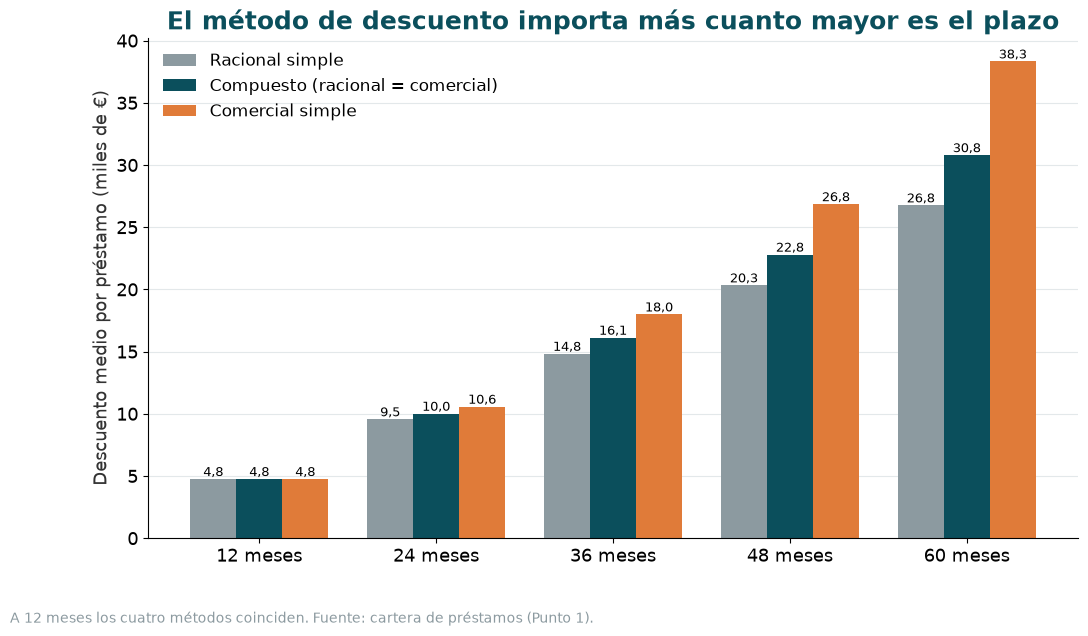

          D_racional_simple  D_racional_compuesto  D_comercial_simple
Duracion                                                             
12                   4750.0                4750.0              4750.0
24                   9550.0               10000.0             10567.0
36                  14818.0               16112.0             17982.0
48                  20322.0               22791.0             26849.0
60                  26751.0               30785.0             38319.0


In [33]:
def grafico_descuento_por_plazo():
    """GRÁFICO 1 (Punto 1): descuento medio por plazo y método. Usa df (columnas D_* y Duracion)."""
    por_plazo = df.groupby("Duracion")[["D_racional_simple", "D_racional_compuesto", "D_comercial_simple"]].mean()
    print("Racional compuesto == comercial compuesto:",
          np.allclose(df["D_racional_compuesto"], df["D_comercial_compuesto"]))
    plazos = por_plazo.index.to_list()
    x = np.arange(len(plazos)); w = 0.26
    fig, ax = plt.subplots()
    series = [("D_racional_simple", "Racional simple", C_GRIS),
              ("D_racional_compuesto", "Compuesto (racional = comercial)", C_OSCURO),
              ("D_comercial_simple", "Comercial simple", C_ALERTA)]
    for j, (col, lab, c) in enumerate(series):
        barras = ax.bar(x + (j - 1) * w, por_plazo[col], w, label=lab, color=c)
        for b in barras:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt_num(b.get_height() / 1000, 1),
                    ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([f"{p} meses" for p in plazos])
    ax.yaxis.set_major_formatter(eje(1000, ""))
    ax.set_ylabel("Descuento medio por préstamo (miles de €)")
    ax.set_title("El método de descuento importa más cuanto mayor es el plazo")
    ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
    fig.text(0.01, -0.02, "A 12 meses los cuatro métodos coinciden. Fuente: cartera de préstamos (Punto 1).",
             fontsize=10, color=C_GRIS)
    guardar(fig, "g1_descuento_por_plazo"); plt.show()
    print(por_plazo.round(0))

grafico_descuento_por_plazo()

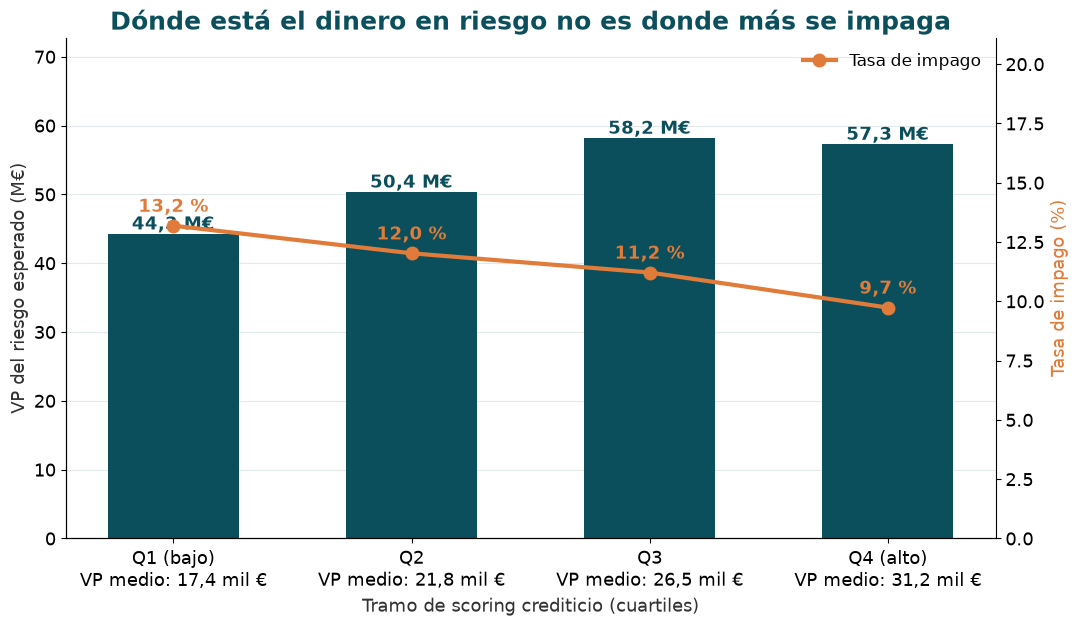

               personas  tasa_impago      va_medio        riesgo
Tramo_Scoring                                                   
Q1 (bajo)         19317     0.131905  17381.900675  4.428290e+07
Q2                19201     0.120254  21812.516934  5.035582e+07
Q3                19572     0.112150  26505.629616  5.818460e+07
Q4 (alto)         18834     0.097377  31235.852571  5.730325e+07
Riesgo esperado total (€): 210.126.561 | el de tu notebook: 210.126.561


In [34]:
def grafico_riesgo_por_scoring():
    """GRÁFICO 2 (Punto 2): riesgo esperado y tasa de impago por tramo de scoring. Usa df."""
    t = df.groupby("Tramo_Scoring", observed=True).agg(
        personas=("ID", "count"), tasa_impago=("Impago", "mean"),
        va_medio=("Va_pendiente", "mean"), riesgo=("VP_riesgo_esperado", "sum"))
    etq = [f"{i}\nVP medio: {fmt_num(v / 1000, 1)} mil €" for i, v in zip(t.index.astype(str), t["va_medio"])]
    fig, ax = plt.subplots()
    barras = ax.bar(etq, t["riesgo"], color=C_OSCURO, width=0.55)
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt_num(b.get_height() / 1e6, 1) + " M€",
                ha="center", va="bottom", fontweight="bold", color=C_OSCURO)
    ax.yaxis.set_major_formatter(eje(1e6, ""))
    ax.set_ylabel("VP del riesgo esperado (M€)"); ax.set_ylim(0, t["riesgo"].max() * 1.25)
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
    ax2.plot(etq, t["tasa_impago"] * 100, color=C_ALERTA, marker="o", lw=3, ms=9, label="Tasa de impago")
    for xx, yy in zip(etq, t["tasa_impago"] * 100):
        ax2.annotate(fmt_num(yy, 1) + " %", (xx, yy), textcoords="offset points", xytext=(0, 10),
                     ha="center", color=C_ALERTA, fontweight="bold")
    ax2.set_ylabel("Tasa de impago (%)", color=C_ALERTA); ax2.set_ylim(0, t["tasa_impago"].max() * 100 * 1.6)
    ax.set_title("Dónde está el dinero en riesgo no es donde más se impaga")
    ax.set_xlabel("Tramo de scoring crediticio (cuartiles)")
    ax2.legend(loc="upper right"); ax.grid(axis="x", visible=False)
    guardar(fig, "g2_riesgo_por_scoring"); plt.show()
    print(t)
    print("Riesgo esperado total (€):", fmt_num(t["riesgo"].sum()),
          "| el de tu notebook:", fmt_num(df["VP_riesgo_esperado"].sum()))

grafico_riesgo_por_scoring()